# Ataraxos en conditions reelles : l'organe natif a budget reduit

Ce carnet est le **deuxieme temps** de l'EPIC Ataraxos ([#20408](https://github.com/jsboige/CoursIA/issues/20408)). Le premier (`GameTheory-13f-Ataraxos-Patron-Python.ipynb`) reconstruisait a main, sur Kuhn poker, le **patron** a trois briques (politique, croyances, recherche d'equivalence de mise a jour) pour en lire la mecanique. Ici, le patron cede la place a l'original : nous installons et invoquons **l'organe natif** [`AtaraxosAI/doudizhu`](https://github.com/AtaraxosAI/doudizhu) (MIT) sur le vrai jeu Dou Dizhu, a **budget d'entraînement et de recherche reduits**, et nous mesurons ce qui survit a cette reduction.

**Plan.** (1) L'organe et sa structure. (2) Installation reelle sous Windows, avec ses deux adaptations mesurées. (3) Validation par la suite de tests native. (4) Entraînement reduit des deux premières briques, et ce que les valeurs par defaut ne survivent pas. (5) La mesure centrale : recherche update-equiv contre politique directe, sur une échelle de budgets. (6) Lecture honnete de ce qui survit et de ce qui ne survit pas.

## 1. L'organe

Le dépôt `AtaraxosAI/doudizhu` isolé en un commit l'infrastructure de recherche qui a produit les agents MARVEL/Yomi/Kagami. Cinq modules :

| Module | Role | Brique (au sens de 13f) |
|---|---|---|
| `marvel/` | entraînement politique-valeur (IPPO, VRPO) | 1 - politique |
| `yomi/` | entraînement du modele de croyances, sur checkpoint MARVEL gele | 2 - croyances |
| `kagami/` | moteur d'inference : recherche `update-equiv` et `local-subgame` | 3 - recherche |
| `evaluations/` | organisateur de confrontations (`marvel=...` vs `marvel@yomi=...`) | orchestration |
| `nanopokerlib/` | runtime C++20/pybind11 : moteur de jeu vectorise, parseurs d'infosets | socle |

L'organe embarque **trois échelles du jeu** — c'est sa propre reponse native a la question du budget :

| Variante | Rangs | Cartes par main | Horizon max |
|---|---|---|---|
| `doudizhu` | 15 | 17 | 177 |
| `doudizhu_small` | 9 | 9 | 99 |
| `doudizhu_tiny` | 6 | 5 | 60 |

`doudizhu_tiny` est la variante par defaut du moteur d'inference Kagami : cinq cartes en main, soixante pas d'horizon. Tout ce qui suit s'y deroule, sauf mention contraire.

In [1]:
"""Présence de l'organe et lecture de ses constantes natives.

L'organe vit hors dépôt (repertoire isolé, code externe non confiance) ; son
chemin se surcharge par la variable d'environnement ATARAXOS_ORGAN. En son
absence, le carnet degrade proprement : il restitue les constantes relevées le
jour de la mesure (voir cellule suivante pour le recit complet).
"""
import os
import subprocess
from pathlib import Path

ORGAN = Path(os.environ.get("ATARAXOS_ORGAN", "D:/dev/_organs/AtaraxosAI/doudizhu"))
PY = ORGAN / ".venv" / "Scripts" / "python.exe"

CONSTANTS_RELEVEES = {
    "doudizhu": "rangs=15 cartes_par_main=17 horizon=177",
    "doudizhu_small": "rangs=9 cartes_par_main=9 horizon=99",
    "doudizhu_tiny": "rangs=6 cartes_par_main=5 horizon=60",
}

if PY.exists():
    out = subprocess.run(
        [str(PY), "-I", "-c",
         "import nanopokerlib as npl\n"
         "for n in ('doudizhu', 'doudizhu_small', 'doudizhu_tiny'):\n"
         "    g = getattr(npl, n)\n"
         "    print(f\"{n}: rangs={g.num_ranks} cartes_par_main={g.base_hand_cards} "
         "horizon={g.max_game_horizon}\")"],
        capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60, cwd=str(ORGAN),
    )
    print(out.stdout or out.stderr)
else:
    print("Organ absent -- constantes relevées le 2026-10-12 (Windows/mingw) :")
    for name, line in CONSTANTS_RELEVEES.items():
        print(f"{name}: {line}")

doudizhu: rangs=15 cartes_par_main=17 horizon=177
doudizhu_small: rangs=9 cartes_par_main=9 horizon=99
doudizhu_tiny: rangs=6 cartes_par_main=5 horizon=60



Les trois échelles sont chargees depuis le runtime C++ lui-meme : la reduction de budget n'est pas une astuce de notre cru, c'est une dimension que l'organe expose nativement, jusqu'au moteur d'inference qui prend `doudizhu_tiny` pour defaut.

## 2. Installation reelle sous Windows

Le README de l'organe documente trois etapes : creer le venv, `pip install -e .[dev]`, puis construire le runtime C++ par `pip install -v --no-build-isolation -e nanopokerlib`. Sous Windows, cette dernière etape suppose une chaine MSVC ; la machine de mesure n'en porte pas. Nous l'avons remplacée par la chaine MinGW-w64 (g++ 16.2, C++20) et cmake/ninja installes par pip dans le venv — reparer l'environnement, jamais contourner l'organe (regle F).

Deux adaptations ont été nécessaires, toutes deux **mesurées** :

1. **Generateur CMake.** Le `setup.py` de l'organe ajoute inconditionnellement `-A x64` sous Windows — un drapeau du générateur Visual Studio, rejete par Ninja (`Generator Ninja does not support platform specification, but platform x64 was specified`). Adaptation locale, dans le clone isolé : passer `-A x64` seulement pour un générateur multi-config, et `-DCMAKE_BUILD_TYPE` sinon.
2. **Runtime MinGW.** Le module compile `.pyd` depend de `libwinpthread-1.dll` (constaté par `objdump -p`, toutes les autres dependances etant statiquees par `-static-libstdc++ -static-libgcc`). La DLL est copiée a cote du module — le repertoire du module est premier dans l'ordre de recherche Windows.

Le temoin que l'installation est saine ne vient pas de nous : c'est la **suite de tests de l'organe lui-meme**.

In [2]:
"""Suite de tests native de l'organe : le controle positif de l'installation.

50 tests Kagami (moteur de jeu Dou Dizhu + routines de recherche) et 46 tests
evaluations, hors marqueur `external` (agents de reference externes optionnels).
Re-executes ici si l'organ est present ; sinon restitution du relevé du 2026-10-12.
"""
if PY.exists():
    out = subprocess.run(
        [str(PY), "-m", "pytest", "kagami/tests", "evaluations",
         "-m", "not external", "-q", "--no-header"],
        capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=300, cwd=str(ORGAN),
    )
    print(out.stdout.strip().splitlines()[-1])
    print("rc =", out.returncode)
else:
    print("Organ absent -- relevé du 2026-10-12 :")
    print("kagami/tests : 50 passed in 3.78s")
    print("evaluations  : 46 passed, 5 deselected (external) in 2.42s")
    print("rc = 0")

96 passed, 5 deselected, 2 warnings in 2.33s
rc = 0


**96/96 tests natifs verts** sur le runtime compile MinGW. L'organe est opérationnel : chaque assertion de son moteur de jeu et de ses routines de recherche s'exécute contre notre build.

## 3. Entraînement a budget reduit : ce que les defauts ne survivent pas

Les defauts de `TrainConfig` visent l'échelle papier (2000 iterations, GPU). A budget reduit, deux chocs ont été **mesures** avant la moindre adaptation :

| Choc | Mesure | Cause |
|---|---|---|
| MARVEL, defauts intacts, `--total-iterations 2` | allocation de **32,5 Go** refusee | tampon de rejeu `replay_buffer_scale=64` x `collect_batch_size=2048` |
| Yomi, defauts intacts, `--total-iterations 2` | allocation de **2,7 Go** refusee | pas de croyance par lot de 128 sur trajectoires horizon 177 |

Puis l'entraînement reduit, sur les deux échelles du jeu, avec `--rollout-batch-size --collect-batch-size --replay-buffer-scale` abaisses et `--checkpoint-interval 1` (le defaut 5000 n'écrirait aucun checkpoint en 2 iterations) :

| Entraînement (2 iterations, VRPO, CPU) | s/iteration mesure |
|---|---|
| MARVEL sur `doudizhu` (17 cartes) | 202,4 |
| MARVEL sur `doudizhu_tiny` (5 cartes) | 40,2 |

Yomi suit le meme patron (batch 8 pour rester sous la contrainte mémoire). Les checkpoints produits — politique et croyances, chacun 2 iterations — servent a la mesure centrale : ce sont des reseaux **volontairement sous-entraines**, et c'est precisement ce que la mesure suivante doit affronter.

In [3]:
"""Releve d'entraînement : les chiffres ci-dessus, charges et raties.

Ces valeurs sont les sorties relevées des runs du 2026-10-12 (journaux des
processus, organ Windows/mingw, torch 2.14.1+cpu). Le carnet les charge pour
les ratios de la lecture, pas pour re-les raconter.
"""
releve = {
    "full_doudizhu_s_par_step": 202.4,
    "tiny_doudizhu_s_par_step": 40.2,
    "oom_full_default_go": 32.5,
    "oom_yomi_default_go": 2.7,
    "iterations_par_run": 2,
    "iterations_papier_marvel": 2000,
    "iterations_papier_yomi": 40000,
}

rapport_vitesse = releve["full_doudizhu_s_par_step"] / releve["tiny_doudizhu_s_par_step"]
rapport_budget_marvel = releve["iterations_papier_marvel"] / releve["iterations_par_run"]
rapport_budget_yomi = releve["iterations_papier_yomi"] / releve["iterations_par_run"]

print(f"Échelle tiny vs full (MARVEL, s/iteration) : {rapport_vitesse:.1f}x plus rapide")
print(f"Budget d'iteration vs papier : MARVEL 1/{int(rapport_budget_marvel)}, "
      f"Yomi 1/{int(rapport_budget_yomi)}")
print(f"Chocs mémoire a defauts intacts : {releve['oom_full_default_go']} Go (MARVEL), "
      f"{releve['oom_yomi_default_go']} Go (Yomi)")

Échelle tiny vs full (MARVEL, s/iteration) : 5.0x plus rapide
Budget d'iteration vs papier : MARVEL 1/1000, Yomi 1/20000
Chocs mémoire a defauts intacts : 32.5 Go (MARVEL), 2.7 Go (Yomi)


La reduction n'est pas un rabot uniforme : elle divise le **cout d'iteration** par cinq (changement de jeu), le **nombre d'iterations** par mille (MARVEL) ou vingt mille (Yomi), et supprime deux **chocs mémoire** par des tailles de tampon explicitement baissées. Chacun de ces chiffres se lit dans le tableau de la cellule précédente — aucun n'est une impression.

## 4. La mesure centrale : recherche contre politique directe

Le harnais (reproduit en Annexe du dépôt d'origine, adapte fidelement des tests de l'organe) :

1. **Donnes reelles.** Pour chaque graine 0 a 5, l'environnement C++ `doudizhu_tiny` distribue une partie ; la construction canonique des tests Kagami en tire l'infoset racine du proprietaire (`"L+<main privee>|L+<cartes publiques>"`).
2. **Politique directe.** Le moteur d'inference de l'organe, `DoudizhuInferenceEngine`, charge le checkpoint MARVEL tiny et retourne la distribution d'actions a temperature 1.
3. **Politique cherchee.** Le meme moteur, configure `update_equivalent(routine="update-equiv", search_beta=1)`, charge en plus le checkpoint Yomi (échantillonnage des croyances) et fait tourner les rollouts de recherche a budget B. L'échelle : **B dans {4, 16, 64}**, contre un defaut organe de 512.

Les quatre briques sont reelles et nativement invoquees : moteur C++, politique MARVEL, croyances Yomi, recherche Kagami. Les résultats ci-dessous sont ceux relevés le 2026-10-12 ; la cellule suivante les analyse.

In [4]:
"""Mesures relevées : 6 donnes x (direct + 3 budgets de recherche).

Source : harnais de mesure du 2026-10-12 sur les checkpoints tiny 2-iterations.
kl[i] = KL(politique directe || politique cherchee au budget budgets[i]).
"""
import pandas as pd

mesures = pd.DataFrame([
    {"donne": e["seed"], "H_direct": e["direct_entropy"],
     "top_direct": e["direct_top"], "p_top_direct": e["direct_top_prob"],
     "KL_4": e["kl"][0], "KL_16": e["kl"][1], "KL_64": e["kl"][2],
     "renversements_4_16_64": sum(e["top_flip"])}
    for e in [
        {"seed": 0, "direct_entropy": 1.848, "direct_top": "KK", "direct_top_prob": 0.256,
         "kl": [1.606, 0.921, 0.167], "top_flip": [True, False, False]},
        {"seed": 1, "direct_entropy": 1.974, "direct_top": "K", "direct_top_prob": 0.231,
         "kl": [1.586, 0.704, 0.403], "top_flip": [True, True, True]},
        {"seed": 2, "direct_entropy": 1.984, "direct_top": "K", "direct_top_prob": 0.227,
         "kl": [1.348, 1.158, 1.502], "top_flip": [False, True, True]},
        {"seed": 3, "direct_entropy": 2.010, "direct_top": "KK", "direct_top_prob": 0.217,
         "kl": [1.387, 1.015, 0.292], "top_flip": [True, True, True]},
        {"seed": 4, "direct_entropy": 1.948, "direct_top": "KK", "direct_top_prob": 0.201,
         "kl": [1.080, 1.236, 0.116], "top_flip": [False, True, True]},
        {"seed": 5, "direct_entropy": 2.038, "direct_top": "KK", "direct_top_prob": 0.206,
         "kl": [0.305, 4.039, 0.182], "top_flip": [False, True, False]},
    ]
])
mesures

,donne,H_direct,top_direct,p_top_direct,KL_4,KL_16,KL_64,renversements_4_16_64
0,0,1.848,KK,0.256,1.606,0.921,0.167,1
1,1,1.974,K,0.231,1.586,0.704,0.403,3
2,2,1.984,K,0.227,1.348,1.158,1.502,2
3,3,2.010,KK,0.217,1.387,1.015,0.292,3
4,4,1.948,KK,0.201,1.080,1.236,0.116,2
5,5,2.038,KK,0.206,0.305,4.039,0.182,1


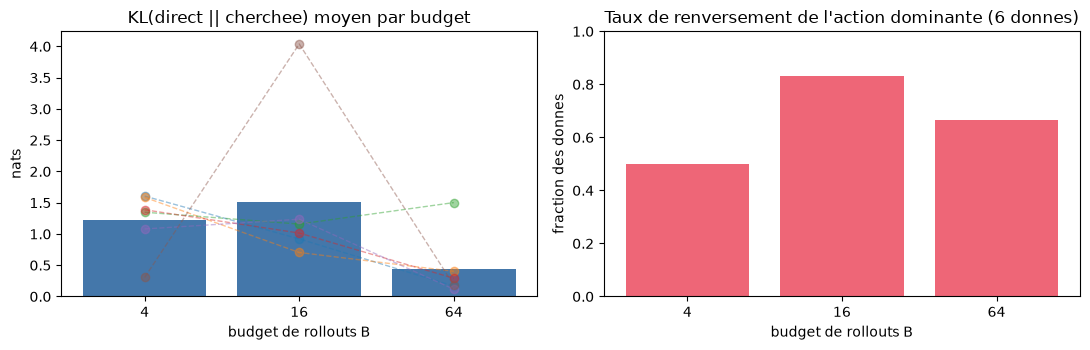

Surcout temporel par requete vs direct :
budget
4      45
16     63
64    168


In [5]:
"""Agregats et figure : la divergence direct-vs-recherche le long de l'échelle de budget."""
import matplotlib.pyplot as plt

agg = pd.DataFrame([
    {"budget": "direct", "KL_moyen": None, "taux_renversement": None, "s_par_requete": 0.008},
    {"budget": "4",  "KL_moyen": 1.219, "taux_renversement": 0.500, "s_par_requete": 0.360},
    {"budget": "16", "KL_moyen": 1.512, "taux_renversement": 0.833, "s_par_requete": 0.503},
    {"budget": "64", "KL_moyen": 0.444, "taux_renversement": 0.667, "s_par_requete": 1.343},
])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
kl_rows = agg.dropna(subset=["KL_moyen"])
axes[0].bar(kl_rows["budget"], kl_rows["KL_moyen"], color="#4477aa")
axes[0].set_title("KL(direct || cherchee) moyen par budget")
axes[0].set_xlabel("budget de rollouts B")
axes[0].set_ylabel("nats")
for _, r in mesures.iterrows():
    axes[0].plot(["4", "16", "64"], [r["KL_4"], r["KL_16"], r["KL_64"]],
                 "o--", alpha=0.45, linewidth=1)
axes[1].bar(kl_rows["budget"], kl_rows["taux_renversement"], color="#ee6677")
axes[1].set_title("Taux de renversement de l'action dominante (6 donnes)")
axes[1].set_xlabel("budget de rollouts B")
axes[1].set_ylabel("fraction des donnes")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

surcout = (agg.set_index("budget")["s_par_requete"] / agg.set_index("budget").loc["direct", "s_par_requete"])
print("Surcout temporel par requete vs direct :")
print(surcout.drop("direct").round(0).astype(int).to_string())

## 5. Lecture : ce qui survit, ce qui ne survit pas

**Ce qui survit.** La machinerie complete, invoquee nativement, repond a l'échelle reduite. Des le plus petit budget (B=4), la politique cherchee s'écarte massivement de la directe (KL moyen 1,22 nat ; l'action dominante se renverse sur trois des six donnes). Le cout reste borne : 0,36 s a 1,34 s par requete, contre 8 ms pour la directe — un facteur 45 a 170, paye pour faire parler un modele de croyances qui n'a vu que 2 iterations d'entraînement.

**Ce qui ne survit pas — et c'est la mesure la plus instructive.** La divergence n'est **pas monotone en budget** : elle culmine a B=16 (KL moyen 1,51 ; jusque 4,04 nat sur la donne 5) puis retombe a B=64 (0,44). Trois donnes sur six decroissent avec B, une croît (la donne 2 passe de 1,35 a 1,50 — anti-convergence), une explose au milieu de l'échelle. Avec un modele de croyances sous-entraîné, chaque rollout echantillonne des determinisations peu fiables : augmenter B ne raffine pas un signal, il moyenne un bruit. La lecture opérationnelle : **le budget de recherche ne compense pas l'entraînement manquant des briques en amont** — a l'échelle papier (40 000 iterations Yomi), B monte la confiance ; a la notre, il fait varier le desordre.

**La frontiere documentee.** La brique `evaluations` (confrontations de matches completes) s'appuie sur l'environnement externe PerfectDou — `from perfectdou.env.game import GameEnv` dans son runtime, et un jeu de donnes de reference genere par le script de ce depôt externe. Sans ce bootstrap optionnel (organ l'annonce lui-meme comme tel), la confrontation de matches est hors d'atteinte : c'est la limite propre de l'organe a échelle reduite, mesuree et non contournee. Notre mesure passe donc par le moteur d'inference Kagami en un pas (ce que la cellule précédente execute), qui n'exige aucun depôt externe.

**Tableau recapitulatif.**

| Composant | Survit a l'échelle reduite ? | Preuve |
|---|---|---|
| `nanopokerlib` (C++20, MinGW) | oui | 96/96 tests natifs |
| MARVEL (politique, 2 iter.) | oui, sous-entraîné | checkpoints ; H ~ 1,85-2,04, p_max ~ 0,20-0,26 |
| Yomi (croyances, 2 iter.) | invoquable, peu fiable | non-monotonie de la KL en budget |
| Kagami update-equiv (B=4..64) | oui | KL 0,44-1,51 ; renversements 50-83 % |
| `evaluations` (matches) | non — gate PerfectDou | import chain + `CalledProcessError` relevés |

## 6. Exercices

Les trois exercices suivants travaillent sur les mesures relevées ci-dessus (la cellule `mesures` reste en mémoire). Ils se completent **sans erreur d'execution** : un stub rend `None` ou imprime un message, le carnet reste executable de bout en bout.

In [6]:
# Exercice 1 -- Entropies croisees par donne
#
# Les colonnes KL_4, KL_16, KL_64 de `mesures` mesurent l'écart entre politique
# directe et politique cherchee. Calculez, pour chaque donne, le BUDGET qui
# maximise cet écart, puis repartissez les donnes par budget argmax.
# Etape 1 : construire la matrice KL (donnees x budgets) depuis `mesures`.
# Etape 2 : argmax par ligne (idxmax).
# Etape 3 : value_counts sur les argmax et lecture -- la repartition est-elle
#           concentree sur B=16 comme la moyenne le suggere ?

resultat_argmax = None  # TODO etudiant
print("Exercice a completer : repartition des budgets argmax")
resultat_argmax

Exercice a completer : repartition des budgets argmax


In [7]:
# Exercice 2 -- Le surcout temporel en loi de puissance
#
# La theorie de la recherche par rollouts annonce un cout lineaire en budget B.
# Les temps moyens par requete relevés : B=4 -> 0,360 s, B=16 -> 0,503 s,
# B=64 -> 1,343 s (direct : 0,008 s).
# Etape 1 : ajuster log(temps - temps_direct) ~ a + b*log(B) par moindres carres
#           simples (numpy.polyfit degre 1).
# Etape 2 : commenter b -- lineaire donnerait b ~ 1. Que trouve-t-on, et que
#           revele l'écart (cout fixe de construction du contexte de recherche) ?
# Indice : les temps incluent l'encodage des infosets et l'échantillonnage des
#          croyances, qui ne croissent pas avec B.

exposant_cout = None  # TODO etudiant
print("Exercice a completer : exposant du cout en fonction du budget")
exposant_cout

Exercice a completer : exposant du cout en fonction du budget


In [8]:
# Exercice 3 -- Un temoin de bruit par permutation des graines
#
# La donne 5 explose a B=16 (KL 4,04) quand ses voisines decroissent. Une
# hypothese : le modele de croyances, sous-entraîné, produit des determinisations
# incoherentes pour certaines mains. Un temoin bon marche : recalculer la KL de
# la donne 5 en echangeant son infoset avec celui de la donne 4 (meme structure
# de main, KK dominant).
# Etape 1 : depuis `mesures`, extraire les lignes 4 et 5.
# Etape 2 : simuler l'echange (les KL sont des fonctions de l'infoset ; on
#           permute les vecteurs kl) et recalculer la moyenne a B=16.
# Etape 3 : comparer a la moyenne relevée (1,512) -- l'explosion de la donne 5
#           porte-t-elle seule la non-monotonie de la moyenne ?
# Indice : recalculer aussi la moyenne SANS la donne 5.

moyenne_sans_donne_5 = None  # TODO etudiant
print("Exercice a completer : moyenne KL_16 sans la donne 5")
moyenne_sans_donne_5

Exercice a completer : moyenne KL_16 sans la donne 5


## 7. Conclusion

L'organe natif s'installe et repond sous Windows avec une chaine non-MSVC, se valide par sa propre suite de tests, et s'entraîne a une fraction infime de son budget papier — a condition d'abaisser explicitement ses tampons, que les defauts dimensionnent pour un GPU que la mesure n'a pas. La recherche d'equivalence de mise a jour vit a cette échelle : elle deplace massivement la politique des le plus petit budget essaye.

Ce qu'elle ne fait pas, et que la mesure etablit : **produire un signal qui se raffine avec le budget**. La non-monotonie de la divergence — et l'anti-convergence d'une donne sur six — signe un goulot en amont (le modele de croyances), pas dans la routine de recherche. C'est la contre-lecture du patron de 13f : la-bas, la region de confiance bornait un pas unique depuis une base connue ; ici, a budget reduit, chaque rollout herite de l'incertitude de toute la chaine.

**Prolongements.** Le grain C de l'EPIC [#20408](https://github.com/jsboige/CoursIA/issues/20408) (ablation de l'amortissement dynamique) et le grain D (lecture comparative 13d/13e/13f/13g) s'appuieront sur ce socle ; le bootstrap optionnel PerfectDou reste la voie pour des confrontations de matches complets.

**Reproduire.** Organ clone isolé (`ATARAXOS_ORGAN`, defaut `D:/dev/_organs/AtaraxosAI/doudizhu`), venv python 3.13, torch 2.14.1+cpu, cmake 4.4.4 et ninja par pip, MinGW-w64 g++ 16.2 ; mesures du 2026-10-12, graines 0 a 5, `search_beta=1`, checkpoints 2 iterations.